In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Data Cleaning
Data cleaning is the process of identifying and correcting or removing errors, inconsistencies, and inaccuracies from a dataset before performing data analysis. This includes tasks such as removing duplicate records, correcting spelling errors, filling in missing values, and addressing outliers and other anomalies. The goal of data cleaning is to ensure that the dataset is accurate, complete, and consistent, which enables more accurate and reliable analysis results.

## 1. Handling Missing Data

In [5]:
series = pd.Series(['aardvark', 'artichoke', np.nan, 'avocado'])
series

0     aardvark
1    artichoke
2          NaN
3      avocado
dtype: str

pandas uses the floating-point 
value NaN (Not a Number) to represent missing data and NA means Not Available

In [6]:
series.isnull()

0    False
1    False
2     True
3    False
dtype: bool

In [7]:
series.isnull().sum()

np.int64(1)

In [4]:
# we can filter our data 
series[series.notnull()]

0     aardvark
1    artichoke
3      avocado
dtype: object

In [5]:
# or we have similar method for this 
series.dropna()

0     aardvark
1    artichoke
3      avocado
dtype: object

In [8]:
# in case of dataframe
from numpy import nan as NA
df = pd.DataFrame([[1., 6.5, 3.], [1., NA, NA],[NA, NA, NA], [NA, 6.5, 3.]])
df

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,NaN,6.5,3.0


### Filtering 

In [7]:
# when you want ot drop columns having all nan value or either single nan value
df.dropna() # by default it will drop any column or row having a null value

,0,1,2
0,1.0,6.5,3.0


In [8]:
df

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,NaN,6.5,3.0


to permanently delete the rows you have to set inplace attribute to True

* Passing how='all' will only drop rows that are all NA

In [9]:
df.dropna(how='all')

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
3,NaN,6.5,3.0


* To drop columns in the same way, pass axis=1

In [10]:
df.dropna(how='all',axis=1)

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,NaN,6.5,3.0


suppose you want to keep only rows containing a certain number of observations then you can use **thresh**  agrument to acheive this. thresh basically means setting threshold value.

In [11]:
df.dropna(thresh=2) # it has drop rows which are having 2 or more NA values and keep the rest.

,0,1,2
0,1.0,6.5,3.0
3,NaN,6.5,3.0


### FIlling

*Instead of this Filtering of Missing Data We can Fill this Data.*

In [12]:
# it will fill missing value with a constant 0 (you can choose any other number inplace of 0)
df.fillna(0) 

,0,1,2
0,1.0,6.5,3.0
1,1.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,6.5,3.0


In [13]:
df

,0,1,2
0,1.0,6.5,3.0
1,1.0,NaN,NaN
2,NaN,NaN,NaN
3,NaN,6.5,3.0


In [14]:
# Calling fillna with a dict, you can use a different fill value for each column
df.fillna({0:0.8 ,1:0.3, 2:0.5})

,0,1,2
0,1.0,6.5,3.0
1,1.0,0.3,0.5
2,0.8,0.3,0.5
3,0.8,6.5,3.0


fillna returns a new object, but you can modify the existing object in-place, by setting inplace=True

In [15]:
df.fillna(0, inplace=True)

In [16]:
df

,0,1,2
0,1.0,6.5,3.0
1,1.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,6.5,3.0


In [30]:
df = pd.DataFrame(np.random.randn(6, 3))
df.iloc[2:, 1] = NA
df.iloc[4:, 2] = NA
df

,0,1,2
0,0.182554,-0.628577,-0.295749
1,0.805406,0.207556,-1.292461
2,1.361994,NaN,-0.314993
3,-0.379857,NaN,2.340296
4,-0.318234,NaN,NaN
5,0.602824,NaN,NaN


In [32]:
# fillna stands for "forward fill" and fills missing values with the previous non-missing value in the column.
df.ffill()

,0,1,2
0,0.182554,-0.628577,-0.295749
1,0.805406,0.207556,-1.292461
2,1.361994,0.207556,-0.314993
3,-0.379857,0.207556,2.340296
4,-0.318234,0.207556,2.340296
5,0.602824,0.207556,2.340296


In [33]:
df

,0,1,2
0,0.182554,-0.628577,-0.295749
1,0.805406,0.207556,-1.292461
2,1.361994,NaN,-0.314993
3,-0.379857,NaN,2.340296
4,-0.318234,NaN,NaN
5,0.602824,NaN,NaN


In [37]:
#  It limits the number of NaN values that can be replaced with the previous non-missing value in the column.
df.ffill(limit=2)

,0,1,2
0,0.182554,-0.628577,-0.295749
1,0.805406,0.207556,-1.292461
2,1.361994,0.207556,-0.314993
3,-0.379857,0.207556,2.340296
4,-0.318234,NaN,2.340296
5,0.602824,NaN,2.340296


In [38]:
series = pd.Series([1., NA, 3.5, NA, 7])
series

0    1.0
1    NaN
2    3.5
3    NaN
4    7.0
dtype: float64

In [39]:
series.mean()

np.float64(3.8333333333333335)

In [40]:
# you can fill missing value with mean , median values
series.fillna(series.mean())

0    1.000000
1    3.833333
2    3.500000
3    3.833333
4    7.000000
dtype: float64

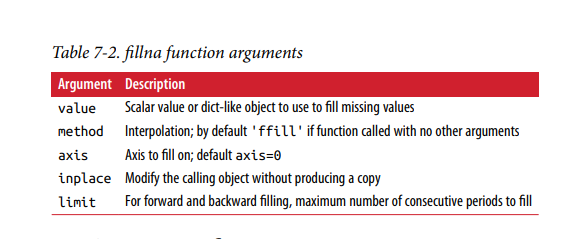

# Data Transformation
The goal of data transformation is to ensure that the data is accurate, consistent, and complete, so that it can be used to extract meaningful insights and inform business decisions. Common data transformation techniques include data cleaning, data normalization, data aggregation, and feature engineering.

## Removing Duplicates

In [47]:
df = pd.DataFrame({'k1': ['one', 'two'] * 3 + ['two'],
 'k2': [1, 1, 2, 3, 3, 4, 4]})
df

,k1,k2
0,one,1
1,two,1
2,one,2
3,two,3
4,one,3
5,two,4
6,two,4


In [48]:
# we can see above df have duplicate rows we can rcheck this duplicate rows
df.duplicated()

0    False
1    False
2    False
3    False
4    False
5    False
6     True
dtype: bool

The DataFrame method duplicated returns a boolean Series indicating whether each
row is a duplicate (has been observed in a previous row) or not.

In [49]:
df.drop_duplicates()

,k1,k2
0,one,1
1,two,1
2,one,2
3,two,3
4,one,3
5,two,4


Both of these methods by default consider all of the columns; alternatively, you can
specify any subset of them to detect duplicates. Suppose we had an additional column
of values and wanted to filter duplicates only based on the 'k1' column

In [50]:
df['v1'] = range(7)

In [51]:
df

,k1,k2,v1
0,one,1,0
1,two,1,1
2,one,2,2
3,two,3,3
4,one,3,4
5,two,4,5
6,two,4,6


In [52]:
df.drop_duplicates(['k1'])

,k1,k2,v1
0,one,1,0
1,two,1,1


In [53]:
df.drop_duplicates(['k1','k2'],keep='last')

,k1,k2,v1
0,one,1,0
1,two,1,1
2,one,2,2
3,two,3,3
4,one,3,4
6,two,4,6


keep in drop_duplicates controls which duplicate values to keep. "first" keeps the first occurrence (default), "last" keeps the last occurrence, and "False" drops all occurrences.

## Transforming Data Using a Function or Mapping

In [54]:
df = pd.DataFrame({'food': ['bacon', 'pulled pork', 'bacon',
      'Pastrami', 'corned beef', 'Bacon',
      'pastrami', 'honey ham', 'nova lox'],
      'ounces': [4, 3, 12, 6, 7.5, 8, 3, 5, 6]})
df

,food,ounces
0,bacon,4.0
1,pulled pork,3.0
2,bacon,12.0
3,Pastrami,6.0
4,corned beef,7.5
5,Bacon,8.0
6,pastrami,3.0
7,honey ham,5.0
8,nova lox,6.0


 Suppose you wanted to add a column indicating the type of animal that each food
 came from. Let’s write down a mapping of each distinct meat type to the kind of
 animal

In [55]:
meat_to_animal = {
 'bacon': 'pig',
 'pulled pork': 'pig',
 'pastrami': 'cow',
 'corned beef': 'cow',
 'honey ham': 'pig',
 'nova lox': 'salmon'
}

In [56]:
# here we need to convert each food in lower case 
# str.lower is a series method to lower the string
list_of_food = df['food'].str.lower()
list_of_food

0          bacon
1    pulled pork
2          bacon
3       pastrami
4    corned beef
5          bacon
6       pastrami
7      honey ham
8       nova lox
Name: food, dtype: str

In [57]:
# it will assign each food , to the animal
list_of_food.map(meat_to_animal)

0       pig
1       pig
2       pig
3       cow
4       cow
5       pig
6       cow
7       pig
8    salmon
Name: food, dtype: str

In [58]:
df['animal'] = list_of_food.map(meat_to_animal)

In [59]:
df

,food,ounces,animal
0,bacon,4.0,pig
1,pulled pork,3.0,pig
2,bacon,12.0,pig
3,Pastrami,6.0,cow
4,corned beef,7.5,cow
5,Bacon,8.0,pig
6,pastrami,3.0,cow
7,honey ham,5.0,pig
8,nova lox,6.0,salmon


In [60]:
# same as above function
df['food'].map(lambda x: meat_to_animal[x.lower()])

0       pig
1       pig
2       pig
3       cow
4       cow
5       pig
6       cow
7       pig
8    salmon
Name: food, dtype: str

**Using map is a convenient way to perform element-wise transformations and other
data cleaning–related operations**

## Replacing Values
replace is a method used to replace values in an array, Series, or DataFrame. The method takes one or more values to replace and one or more replacement values. 

In [38]:
data = pd.Series([1., -999., 2., -999., -1000., 3.])
data

0       1.0
1    -999.0
2       2.0
3    -999.0
4   -1000.0
5       3.0
dtype: float64

In [39]:
# since in above data the -999 values might be sentinel values for missing data , so we will replcae them with np.nan values indicating this values are not available
data.replace(-999,np.nan)

0       1.0
1       NaN
2       2.0
3       NaN
4   -1000.0
5       3.0
dtype: float64

In [40]:
# you can pass list , for replacing multiple values at once
data.replace([-999,-1000],np.nan)

0    1.0
1    NaN
2    2.0
3    NaN
4    NaN
5    3.0
dtype: float64

In [41]:
data.replace([-999,-1000],[np.nan,0])

0    1.0
1    NaN
2    2.0
3    NaN
4    0.0
5    3.0
dtype: float64

In [42]:
# you can use dictionary also as argument 
data.replace({-999: np.nan, -1000: 0})

0    1.0
1    NaN
2    2.0
3    NaN
4    0.0
5    3.0
dtype: float64

**The data.replace method is distinct from data.str.replace,
which performs string substitution element-wise**

In [66]:
df

,food,ounces,animal
0,bacon,4.0,pig
1,pulled pork,3.0,pig
2,bacon,12.0,pig
3,Pastrami,6.0,cow
4,corned beef,7.5,cow
5,Bacon,8.0,pig
6,pastrami,3.0,cow
7,honey ham,5.0,pig
8,nova lox,6.0,salmon


In [65]:
# the axes in-place without creating a new data structure, we will transform our axes indexes
transform = lambda x: "Sno "+str(x)

In [67]:
df.index = df.index.map(transform)
     

In [62]:
df

,food,ounces,animal
0,bacon,4.0,pig
1,pulled pork,3.0,pig
2,bacon,12.0,pig
3,Pastrami,6.0,cow
4,corned beef,7.5,cow
5,Bacon,8.0,pig
6,pastrami,3.0,cow
7,honey ham,5.0,pig
8,nova lox,6.0,salmon


In [68]:
# to save the changes in original data you can set inplace = True
df.rename(index=str.title, columns=str.upper)


,FOOD,OUNCES,ANIMAL
Sno 0,bacon,4.0,pig
Sno 1,pulled pork,3.0,pig
Sno 2,bacon,12.0,pig
Sno 3,Pastrami,6.0,cow
Sno 4,corned beef,7.5,cow
Sno 5,Bacon,8.0,pig
Sno 6,pastrami,3.0,cow
Sno 7,honey ham,5.0,pig
Sno 8,nova lox,6.0,salmon


# Discretization and Binning
Continuous data is often discretized or otherwise separated into “bins” for analysis.
Suppose you have data about a group of people in a study, and you want to group
them into discrete age buckets

In [69]:
ages = [20, 22, 25, 27, 21, 23, 37, 31, 61, 45, 41, 32]
bins = [18, 25, 35, 60, 100]

In [70]:
categories = pd.cut(ages,bins)

In [71]:
categories

[(18, 25], (18, 25], (18, 25], (25, 35], (18, 25], ..., (25, 35], (60, 100], (35, 60], (35, 60], (25, 35]]
Length: 12
Categories (4, interval[int64, right]): [(18, 25] < (25, 35] < (35, 60] < (60, 100]]

The object pandas returns is a special Categorical object. The output you see
describes the bins computed by pandas.cut. You can treat it like an array of strings
indicating the bin name; internally it contains a categories array specifying the dis‐
tinct category names along with a labeling for the ages data in the codes attribute

In [72]:
# codes showing each value of array belong to which bin
categories.codes

array([0, 0, 0, 1, 0, 0, 2, 1, 3, 2, 2, 1], dtype=int8)

In [75]:
# this are the bins or categories in which our data is divided
categories.categories

IntervalIndex([(18, 25], (25, 35], (35, 60], (60, 100]],
              dtype='interval[int64, right]')

In [76]:
# value_counts return the series containing count of unique categories.
pd.value_counts(categories)

AttributeError: module 'pandas' has no attribute 'value_counts'

a parenthesis means that the side
is open, while the square bracket means it is closed (inclusive). You can change which
side is closed by passing right=False

In [77]:
pd.cut(ages, [18, 26, 36, 61, 100], right=False)

[[18, 26), [18, 26), [18, 26), [26, 36), [18, 26), ..., [26, 36), [61, 100), [36, 61), [36, 61), [26, 36)]
Length: 12
Categories (4, interval[int64, left]): [[18, 26) < [26, 36) < [36, 61) < [61, 100)]

In [78]:
# we can als0 pass our own bin name , by passing a list / array to the labels
group_names = ['Youth', 'YoungAdult', 'MiddleAged', 'Senior']
cat = pd.cut(ages, bins, labels=group_names)
cat

['Youth', 'Youth', 'Youth', 'YoungAdult', 'Youth', ..., 'YoungAdult', 'Senior', 'MiddleAged', 'MiddleAged', 'YoungAdult']
Length: 12
Categories (4, str): ['Youth' < 'YoungAdult' < 'MiddleAged' < 'Senior']

In [79]:
cat.codes

array([0, 0, 0, 1, 0, 0, 2, 1, 3, 2, 2, 1], dtype=int8)

In [80]:
cat.categories

Index(['Youth', 'YoungAdult', 'MiddleAged', 'Senior'], dtype='str')

In [81]:
cat.value_counts()

Youth         5
YoungAdult    3
MiddleAged    3
Senior        1
Name: count, dtype: int64

If you pass an integer number of bins to cut instead of explicit bin edges, it will com‐
pute equal-length bins based on the minimum and maximum values in the data.


In [82]:
data = np.random.rand(20)
pd.cut(data, 4, precision=2)

[(0.56, 0.78], (0.56, 0.78], (0.34, 0.56], (0.56, 0.78], (0.56, 0.78], ..., (0.34, 0.56], (0.12, 0.34], (0.78, 1.0], (0.56, 0.78], (0.12, 0.34]]
Length: 20
Categories (4, interval[float64, right]): [(0.12, 0.34] < (0.34, 0.56] < (0.56, 0.78] < (0.78, 1.0]]

The precision=2 option limits the decimal precision to two digits.
A closely related function, qcut, bins the data based on sample quantiles. Depending
on the distribution of the data, using cut will not usually result in each bin having the
same number of data points. Since qcut uses sample quantiles instead, by definition
you will obtain roughly equal-size bins

In [83]:
data = np.random.randn(1000) # Normally distributed

In [84]:
 cats = pd.qcut(data, 4) # Cut into quartiles

In [85]:
cats

[(-3.053, -0.632], (-0.0244, 0.681], (-0.0244, 0.681], (-0.632, -0.0244], (0.681, 3.268], ..., (0.681, 3.268], (-0.0244, 0.681], (0.681, 3.268], (-0.0244, 0.681], (-3.053, -0.632]]
Length: 1000
Categories (4, interval[float64, right]): [(-3.053, -0.632] < (-0.632, -0.0244] < (-0.0244, 0.681] < (0.681, 3.268]]

In [89]:
pd.value_counts(cats)

AttributeError: module 'pandas' has no attribute 'value_counts'

Similar to cut you can pass your own quantiles (numbers between 0 and 1, inclusive)

In [90]:
c = pd.qcut(data, [0, 0.1, 0.5, 0.9, 1.])
c.value_counts()

(-3.053, -1.224]     100
(-1.224, -0.0244]    400
(-0.0244, 1.273]     400
(1.273, 3.268]       100
Name: count, dtype: int64

# Detecting and Filtering Outliers


In [91]:
data = pd.DataFrame(np.random.randn(1000, 4))
data

,0,1,2,3
0,0.801013,-0.299539,0.064572,-1.356676
1,1.761329,0.131529,0.867295,-1.874992
2,-2.056092,0.305858,-0.328886,-0.365901
3,1.009120,1.385920,0.378612,0.684874
4,0.673393,0.276070,-0.152915,-1.178021
...,...,...,...,...
995,0.486422,-1.506312,-1.036595,-2.161757
996,0.285341,0.269720,0.861871,-0.159973
997,-2.089437,-1.643998,-1.627345,0.438532
998,-1.874509,-0.467956,0.060135,-1.003040


In [92]:
data.describe()

,0,1,2,3
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,-0.015912,-0.006239,-0.011442,-0.034874
std,1.008534,1.030959,1.053680,0.997545
min,-3.460008,-2.902775,-3.045588,-3.232751
25%,-0.710849,-0.692925,-0.753353,-0.727320
50%,0.039948,0.036876,-0.018712,-0.027311
75%,0.653576,0.714887,0.710979,0.625601
max,3.279235,3.324719,3.331354,2.908553


In [93]:
# if we want to find values in column 2 , which are greater then 4 in absolute value
data[np.abs(data[2])>4]

,0,1,2,3


In [95]:
# To select all rows having a value exceeding 3 or –3, you can use the any method on a
# boolean DataFrame
data[(np.abs(data)>3).any(1)]


TypeError: DataFrame.any() takes 1 positional argument but 2 were given

In [96]:
# The statement np.sign(data) produces 1 and –1 values based on whether the values
# in data are positive or negative
np.sign(data).head()

,0,1,2,3
0,1.0,-1.0,1.0,-1.0
1,1.0,1.0,1.0,-1.0
2,-1.0,1.0,-1.0,-1.0
3,1.0,1.0,1.0,1.0
4,1.0,1.0,-1.0,-1.0


# Permutation and Random Sampling

In [97]:
df = pd.DataFrame(np.arange(5 * 4).reshape((5, 4)))
df

,0,1,2,3
0,0,1,2,3
1,4,5,6,7
2,8,9,10,11
3,12,13,14,15
4,16,17,18,19


In [71]:
sampler = np.random.permutation(5)
sampler

array([1, 0, 4, 2, 3])

In [98]:
# here take work same as iloc , it will take rows number in sampler
df.take(sampler)

NameError: name 'sampler' is not defined

In [99]:
df.iloc[sampler]

NameError: name 'sampler' is not defined

In [100]:
# To select a random subset without replacement
df.sample(n=3)

,0,1,2,3
4,16,17,18,19
1,4,5,6,7
2,8,9,10,11


In [101]:
# To generate a sample with replacement (to allow repeat choices), pass replace=True to sample
choices = pd.Series([5, 7, -1, 6, 4])
choices

0    5
1    7
2   -1
3    6
4    4
dtype: int64

In [102]:
draws = choices.sample(n=10, replace=True)
draws

0    5
4    4
4    4
1    7
4    4
3    6
2   -1
2   -1
4    4
0    5
dtype: int64

# Computing Indicator/Dummy Variables
In data analysis, computing indicator/dummy variables involves creating binary variables to represent the presence or absence of a categorical variable. This process is also known as one-hot encoding. Dummy variables are used in statistical models to represent categorical data as numerical data, which can be analyzed more easily. In Python, Pandas provides the get_dummies() function to create dummy variables. This function takes a categorical column in a DataFrame and returns a new DataFrame with binary columns for each unique value in the original column.

In [103]:
df = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'b'],
'data1': range(6)})
df

,key,data1
0,b,0
1,b,1
2,a,2
3,c,3
4,a,4
5,b,5


In [104]:
pd.get_dummies(df['key'])


,a,b,c
0,False,True,False
1,False,True,False
2,True,False,False
3,False,False,True
4,True,False,False
5,False,True,False


In [105]:
dummies = pd.get_dummies(df['key'], prefix='key')
dummies

,key_a,key_b,key_c
0,False,True,False
1,False,True,False
2,True,False,False
3,False,False,True
4,True,False,False
5,False,True,False


In [106]:
df_with_dummy = df[['data1']].join(dummies)
df_with_dummy

,data1,key_a,key_b,key_c
0,0,False,True,False
1,1,False,True,False
2,2,True,False,False
3,3,False,False,True
4,4,True,False,False
5,5,False,True,False
